In [ ]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

import kagglehub

path = kagglehub.competition_download("csiro-biomass")
print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/csiro-biomass


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
from keras import layers
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow version:", tf.__version__)
print("Keras version:     ", keras.__version__)


TensorFlow version: 2.21.0
Keras version:      3.13.2


In [ ]:
SEED = 42
IMG_SIZE = (100, 200)
BATCH_SIZE = 10

EPOCHS_BASELINE = 150
EPOCHS_FEATURE = 100
EPOCHS_FINETUNE = 100

LR_FEATURE = 1e-3
LR_FINETUNE = 1e-5
FINE_TUNE_AT = 100

TRAIN_SPLIT = 70
VAL_SPLIT = 20
# though there is a test folder included in the downloaded competition dataset, it only includes 1 image, therefore i used a section of the training data for the testing
TEST_SPLIT = 10

keras.utils.set_random_seed(SEED)

In [ ]:


# Load dataset and pivot from long format to wide format so each image has one row
# with multiple target values corresponding to different biomass components.

df = pd.read_csv(path + "/train.csv")
df = df.pivot_table(
    index="image_path",
    values="target",
    columns="target_name"
).reset_index()

# Define biomass target categories for regression

target_cols = ['Dry_Green_g', 'Dry_Dead_g', 'Dry_Clover_g', 'GDM_g', 'Dry_Total_g']

# Prepare file paths and target values as NumPy arrays

image_paths = (path + "/" + df["image_path"]).values
y = df[target_cols].values.astype(np.float32)

# Partition the dataset into training, validation, and test sets sequentially
# based on predefined split percentages.
train_paths, y_train = (
    image_paths[: int(len(image_paths) * TRAIN_SPLIT / 100)],
    y[: int(len(y) * TRAIN_SPLIT / 100)],
)
val_paths, y_val = (
    image_paths[int(len(image_paths) * TRAIN_SPLIT / 100): int(len(image_paths) * (TRAIN_SPLIT + VAL_SPLIT) / 100)],
    y[int(len(y) * TRAIN_SPLIT / 100): int(len(y) * (TRAIN_SPLIT + VAL_SPLIT) / 100)],
)
test_paths, y_test = image_paths[int(len(image_paths) * (TRAIN_SPLIT + VAL_SPLIT) / 100):], y[int(len(y) * (TRAIN_SPLIT + VAL_SPLIT) / 100):]


# 2. Define a TensorFlow preprocessing function to load, decode, resize, and normalize images
def load_and_resize(file_path, label):
    img_bytes = tf.io.read_file(file_path)
    img = tf.image.decode_image(
        img_bytes, channels=3, expand_animations=False
    )
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0  # Scale to 0-1
    return img, label


AUTOTUNE = tf.data.AUTOTUNE
# Define data augmentation pipeline to improve generalization and prevent overfitting
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),    # ±10% rotation
    layers.RandomZoom(0.1),        # ±10% zoom
], name="adatbovites")

# Wrapper function to apply data augmentation to training samples
def augment(image, label):
    return data_augmentation(image, training=True), label


# Build optimized tf.data pipelines for efficient data loading and GPU utilization
# --- TRAINING DATASET (includes preprocessing, caching, augmentation, and shuffling) ---
train_ds = (
    tf.data.Dataset.from_tensor_slices((train_paths, y_train))
    .map(load_and_resize, num_parallel_calls=AUTOTUNE)
    .map(augment, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# --- VALIDATION DATASET ---
val_ds = (
    tf.data.Dataset.from_tensor_slices((val_paths, y_val))
    .map(load_and_resize, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# --- TEST DATASET ---
test_ds = (
    tf.data.Dataset.from_tensor_slices((test_paths, y_test))
    .map(load_and_resize, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Inspect the shape of a single generated batch to verify pipeline correctness
for images, labels in train_ds.take(1):
    print("Shape of pictures in a batch:", images.shape)
    print("Shape of labels in a batch:", labels.shape)



Shape of pictures in a batch: (10, 100, 200, 3)
Shape of labels in a batch: (10, 5)


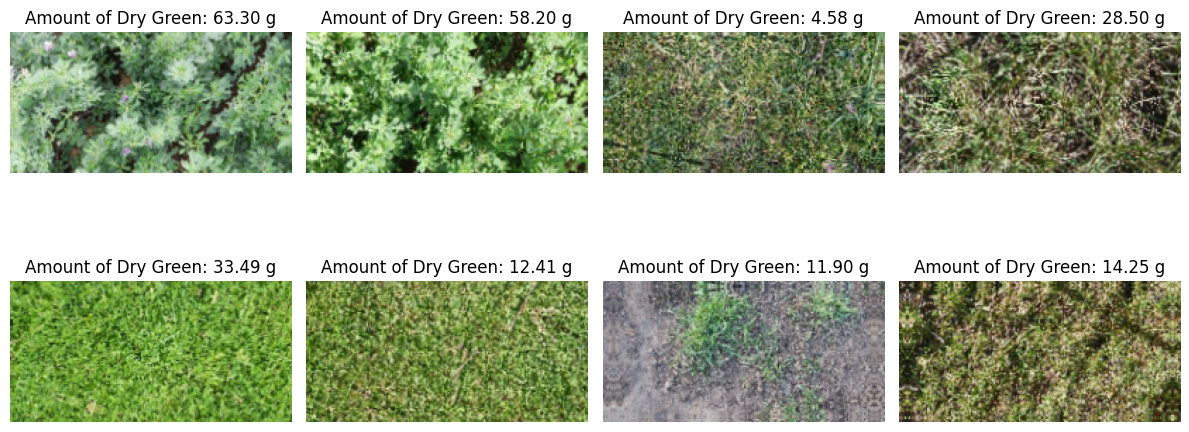

In [ ]:
import matplotlib.pyplot as plt

# Extract a single batch of images and labels from the training dataset pipeline
# to visualize the augmented data.

for images, labels in train_ds.take(1):
    batch_images = images.numpy()
    batch_labels = labels.numpy()
    break

# Set up a grid layout to display multiple sample images from the batch

plt.figure(figsize=(12, 6))
for i in range(min(8, len(batch_images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(batch_images[i])
    # Display the corresponding target value for 'Dry_Green_g' (index 0) in the title
    plt.title(f"Amount of Dry Green: {batch_labels[i][0]:.2f} g")
    plt.axis("off")
plt.tight_layout()
plt.show()